# PINZAS 1 — Calibración de la escala y catálogo de grabaciones

Dos cosas que usan todos los demás notebooks:

1. **La escala** (µm por píxel), medida con la foto de la retícula `CALIBRACION 0,01mm.tif`.
2. **El catálogo** de lo que se grabó el 12/11/2026: qué es cada carpeta de `C:\datos_pinzas\GRABACIONES`, cuántos cuadros tiene, a cuántos cuadros por segundo y con qué renglón del cuaderno se corresponde.

Salidas: `datos/calibracion.csv`, `datos/calibracion.json`, `datos/catalogo.csv` y `figuras/PINZAS 1/`.

In [1]:
import json, os, re, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pinzas_datos import RAIZ, DATOS, CATALOGO

# estilo de ESTILO_FIGURAS.md (raíz del repo)
plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE = "#2A9D8F", "#E76F51", "#264653"
FIGURAS = os.path.join(RAIZ, "figuras", "PINZAS 1")
os.makedirs(FIGURAS, exist_ok=True)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIGURAS, nombre + ".png"), bbox_inches="tight", dpi=300)

## 1. Escala

La retícula tiene una línea cada 0.01 mm = 10 µm. Se toma el canal verde, se promedian franjas de 40 filas de la parte de abajo (donde están todas las líneas) y en cada franja se busca el **período** del patrón: el que maximiza la amplitud de un coseno ajustado al perfil. Las líneas están algo inclinadas; la inclinación sale de cuánto se corre la fase del patrón de una franja a la siguiente, y el período perpendicular a las líneas es el medido a lo largo de $x$ por el coseno de ese ángulo.

In [2]:
img = np.asarray(Image.open(os.path.join(RAIZ, "CALIBRACION 0,01mm.tif")).convert("RGB"), float)[:, :, 1]
x = np.arange(img.shape[1])
periodos = np.linspace(95, 115, 4001)


def perfil(y0, alto=40):
    p = img[y0:y0 + alto].mean(0)
    return p - np.convolve(np.pad(p, 100, mode="edge"), np.ones(201) / 201, "same")[100:-100]   # sin la iluminación


filas = []
for y0 in range(560, 1000, 40):
    p = perfil(y0)
    amp = np.array([abs(np.sum(p * np.exp(-2j * np.pi * x / T))) for T in periodos])
    T = periodos[int(np.argmax(amp))]
    fase = np.angle(np.sum(p * np.exp(-2j * np.pi * x / T)))
    filas.append(dict(fila_centro=y0 + 20, periodo_px=T, fase_rad=fase))
cal = pd.DataFrame(filas)
cal["fase_rad"] = np.unwrap(cal.fase_rad)
T_x, err_T = cal.periodo_px.mean(), cal.periodo_px.std(ddof=1) / np.sqrt(len(cal))
pend, cov = np.polyfit(cal.fila_centro, cal.fase_rad * T_x / (2 * np.pi), 1, cov=True)
angulo, err_angulo = np.arctan(pend[0]), np.sqrt(cov[0, 0])
T_perp = T_x * np.cos(angulo)
err_T_perp = np.hypot(err_T * np.cos(angulo), T_x * np.sin(angulo) * err_angulo)
escala_nm = 10000 / T_perp
err_escala_nm = escala_nm * err_T_perp / T_perp
print("período a lo largo de x: %.2f ± %.2f px (11 franjas)" % (T_x, err_T))
print("inclinación de las líneas: %.2f ± %.2f°" % (np.degrees(angulo), np.degrees(err_angulo)))
print("período perpendicular a las líneas: %.2f ± %.2f px" % (T_perp, err_T_perp))
print("ESCALA: %.2f ± %.2f nm/px  (campo de 1280 × 1024 px = %.0f × %.0f µm)"
      % (escala_nm, err_escala_nm, 1280 * escala_nm / 1000, 1024 * escala_nm / 1000))
cal.to_csv(os.path.join(DATOS, "calibracion.csv"), index=False, float_format="%.5g")
with open(os.path.join(DATOS, "calibracion.json"), "w", encoding="utf-8") as f:
    json.dump(dict(escala_nm_por_px=round(escala_nm, 3), err_nm_por_px=round(err_escala_nm, 3),
                   periodo_px=round(T_perp, 3), inclinacion_grados=round(float(np.degrees(angulo)), 2),
                   division_um=10, imagen="CALIBRACION 0,01mm.tif",
                   nota="el error es solo estadístico: no incluye la tolerancia de fabricación de la retícula"),
              f, ensure_ascii=False, indent=1)

período a lo largo de x: 105.96 ± 0.05 px (11 franjas)
inclinación de las líneas: 4.00 ± 0.13°
período perpendicular a las líneas: 105.70 ± 0.05 px
ESCALA: 94.61 ± 0.04 nm/px  (campo de 1280 × 1024 px = 121 × 97 µm)


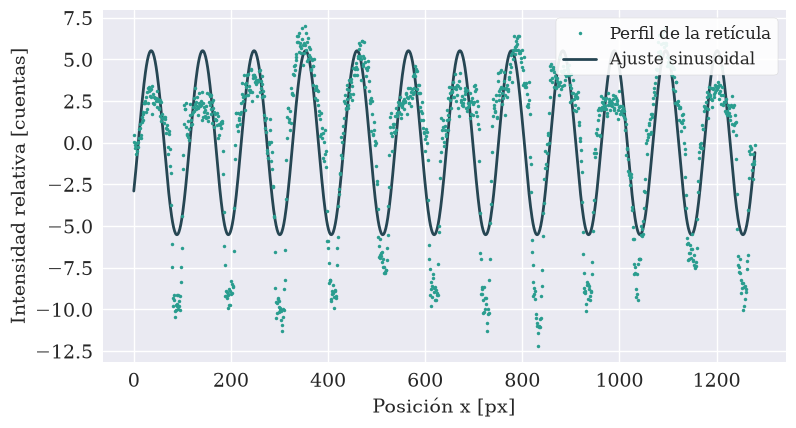

In [3]:
p = perfil(760)
A = 2 * np.sum(p * np.exp(-2j * np.pi * x / T_x)) / len(x)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, p, "o", ms=2.5, color=SERIE1, zorder=3, label="Perfil de la retícula")
ax.plot(x, np.real(A * np.exp(2j * np.pi * x / T_x)), color=AJUSTE, lw=2, zorder=2, label="Ajuste sinusoidal")
ax.set_xlabel(r"Posición $x$ [px]")
ax.set_ylabel("Intensidad relativa [cuentas]")
ax.legend(loc="upper right", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "calibracion_perfil")

**Qué incluye el error y qué no.** El ± es la dispersión entre franjas y el error del ángulo. No incluye la tolerancia de fabricación de la retícula (no la conocemos) ni un posible cambio de aumento entre la foto de la retícula y las mediciones. Las líneas tienen un borde ancho y el perfil no es un coseno puro, pero el período no depende de eso.

## 2. Catálogo de grabaciones

ThorCam parte cada grabación en archivos de 167 cuadros y los TIFF **no traen el tiempo de cada cuadro**. Los cuadros por segundo se estiman con la fecha de escritura de cada archivo: 167 cuadros dividido la mediana del tiempo entre archivos consecutivos. Si un archivo tardó más que los demás, hubo una pausa (cuadros perdidos o demora al escribir) que el tiempo nominal no refleja: se anota.

La celda lee `C:\datos_pinzas\GRABACIONES` si está; si no, usa el `datos/catalogo.csv` ya guardado.

In [4]:
GRABACIONES = r"C:\datos_pinzas\GRABACIONES"
orden = lambda n: [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", os.path.splitext(n)[0])]
ruta_csv = os.path.join(DATOS, "catalogo.csv")
if os.path.isdir(GRABACIONES):
    filas = []
    for g in sorted(os.listdir(GRABACIONES)):
        carpeta = os.path.join(GRABACIONES, g)
        fs_ = sorted([f for f in os.listdir(carpeta) if f.lower().endswith(".tif")], key=orden)
        rutas = [os.path.join(carpeta, f) for f in fs_]
        with Image.open(rutas[0]) as im:
            por_archivo, tam = im.n_frames, im.size
        with Image.open(rutas[-1]) as im:
            ultimo = im.n_frames
        m = np.array([os.path.getmtime(r) for r in rutas])
        dt = np.diff(m[:-1])
        cuadros = por_archivo * (len(rutas) - 1) + ultimo
        pausas = "; ".join("%s: +%.1f s" % (fs_[i + 1], d - np.median(dt)) for i, d in enumerate(dt) if d - np.median(dt) > 0.3)
        info = CATALOGO.get(g, {})
        filas.append(dict(grabacion=g, primer_archivo=fs_[0], archivos=len(rutas), cuadros=cuadros,
                          ancho_px=tam[0], alto_px=tam[1], fps=round(por_archivo / np.median(dt), 3),
                          duracion_s=round(cuadros / (por_archivo / np.median(dt)), 1),
                          hora_inicio=datetime.datetime.fromtimestamp(os.path.getctime(rutas[0])).strftime("%H:%M:%S"),
                          pausas=pausas, tipo=info.get("tipo", "browniano"),
                          laser_x_px=info.get("trampa_px", (np.nan, np.nan))[0],
                          laser_y_px=info.get("trampa_px", (np.nan, np.nan))[1],
                          que_es=info.get("que", "sin láser: movimiento browniano")))
    cat = pd.DataFrame(filas).sort_values("hora_inicio").reset_index(drop=True)
    cat.to_csv(ruta_csv, index=False)
cat = pd.read_csv(ruta_csv)
print("%d grabaciones, %d cuadros, %.0f min en total" % (len(cat), cat.cuadros.sum(), cat.duracion_s.sum() / 60))
cat[["grabacion", "hora_inicio", "cuadros", "fps", "duracion_s", "tipo", "que_es", "pausas"]]

11 grabaciones, 35455 cuadros, 52 min en total


,grabacion,hora_inicio,cuadros,fps,duracion_s,tipo,que_es,pausas
0,BROWNIANO 1,16:06:23,5102,10.021,509.1,browniano,sin láser: movimiento browniano,BROWNIANO1_26.tif: +3.7 s; BROWNIANO1_27.tif: ...
1,LASER NE,17:17:13,2258,10.022,225.3,patadas,"dos patadas (a = 49 y 100 µm/s², paso 200 µm);...",NaN
2,BARRIDO 1,17:29:23,3219,10.021,321.2,patadas,"barrido de aceleración: 15 patadas, paso 100 µ...",ACELERACION_17.tif: +0.6 s
3,MUEVO A MANO,17:47:23,1209,10.021,120.6,patadas,platina movida a mano,NaN
4,BROWNIANO 2,17:49:41,2121,10.021,211.7,browniano,sin láser: movimiento browniano,NaN
5,BARRIDO 2,18:00:55,1753,10.019,175.0,patadas,"3 patadas, paso 250 µm, a = 450 µm/s²",NaN
6,LASER 5,18:22:33,3165,13.128,241.1,potencia,"barrido de potencia 1 (30 a 0 mW de a 30 s), p...",NaN
7,BARRIDO POTENCIAS 2,19:05:54,3006,12.501,240.5,potencia,"barrido de potencia 2 (30 a < 3 mW de a 30 s),...",NaN
8,BARRIDO STEPSIZE,19:10:53,3834,12.502,306.7,patadas,"barrido de paso: 7 patadas, a = 450 µm/s², pas...",NaN
9,BARRIDO STEPSIZE 2,19:19:22,3376,12.503,270.0,patadas,"barrido de paso: 13 patadas, a = 250 µm/s², pa...",NaN


### Notas del catálogo

- **Orden real** (por la hora del primer archivo): es el orden de la tabla. Coincide con el del cuaderno salvo que `MUEVO A MANO` y `BROWNIANO 2` se grabaron antes que `BARRIDO 2`.
- **`LASER 5`** contiene `BARRIDO_POTENCIAS.tif`: es el **primer barrido de potencia** del cuaderno.
- **`BARRIDO STEPSIZE 3`** no tiene renglones en el cuaderno; por el orden es lo que sigue a «ahora nos vamos a mover verticalmente».
- **El láser** está en dos posiciones de la imagen: (497, 477) px en `LASER NE` y `BARRIDO 1`, y (478, 485) px desde `MUEVO A MANO` en adelante. Se ubicó con la mancha roja que deja la partícula atrapada al dispersar el láser (mediana temporal del canal rojo sobre el verde).
- **Cuadros por segundo:** 10.02 hasta `BARRIDO 2`, 13.13 en `LASER 5` y 12.50 después. Son estimaciones; el error relativo del método es del orden de 0.1 %.
- Los videos están también como MP4 para mirar en `C:\datos_pinzas\VISTAS\`.